# 02 — What are the models learning?

**Question.** Separate persistent model scores from changing scores and test whether the increment is robust.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config/injury_profile_departure.yaml').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from src.injury_analysis.profile_departure import inputs,read_table,OUT
from src.injury_analysis.profile_workflow import ensure_stage
from src.injury_analysis import profile_plots as plots
FORCE_RECOMPUTE=False
a,events,spec,matches=inputs()
pd.set_option('display.max_columns',16)


## Exact score decomposition and original matched controls
The combined logistic predictor equals intercept + profile contribution + departure contribution. Missing flags belong to their source block. This identity is verified numerically; contributions are log-odds terms, not causal risk shares.

Use the exact original matched case/control identities and outing keys. Both observed windows must fall in 2022–2025, outside training. Main curves require complete P+D measurements for both members and the same pairs at every plotted point. This avoids imputed measurements or changing pair composition creating a trajectory. Prediction evaluation itself retains incomplete rows.

Calendar bins are 31–60, 15–30, 8–14 and 1–7 days before the recorded event. Appearance positions are the final five outings within 60 days; they are not equally spaced in calendar time. Bands are pitcher-bootstrap simultaneous bands within each curve, without smoothing. Event counts are printed in each panel.

Using verified models results (19 artifacts).


Using verified scores results (9 artifacts).


,category,pairs,appearance_rows,complete_rows
0,Elbow / UCL,92,1946,1920
1,Forearm,37,926,917
2,Hand / wrist,22,522,519
3,Lower body,93,2151,2118
4,Other arm,37,786,780
5,Shoulder,95,2118,2091
6,Trunk / neck,67,1641,1619


,check,max_absolute_error
0,Exact combined linear predictor reconstruction,1.776357e-15


,category,partition,block,rows,pitchers,between_pitcher_fraction,variance,profile_departure_covariance,total_logit_variance
4,Elbow / UCL,test,profile_score,27665,789,0.862254,0.082841,0.001431,0.154869
5,Elbow / UCL,test,departure_score,27665,789,0.088230,0.069166,0.001431,0.154869
10,Forearm,test,profile_score,27236,779,0.968563,0.578741,0.001321,0.676246
11,Forearm,test,departure_score,27236,779,0.041139,0.094862,0.001321,0.676246
16,Hand / wrist,test,profile_score,27129,779,0.941466,0.596560,-0.004088,0.705409
17,Hand / wrist,test,departure_score,27129,779,0.043359,0.117026,-0.004088,0.705409
22,Lower body,test,profile_score,27593,783,0.976695,0.610545,0.003691,0.659241
23,Lower body,test,departure_score,27593,783,0.079907,0.041313,0.003691,0.659241
28,Other arm,test,profile_score,27216,781,0.949191,0.148888,-0.000115,0.211666
29,Other arm,test,departure_score,27216,781,0.074524,0.063007,-0.000115,0.211666


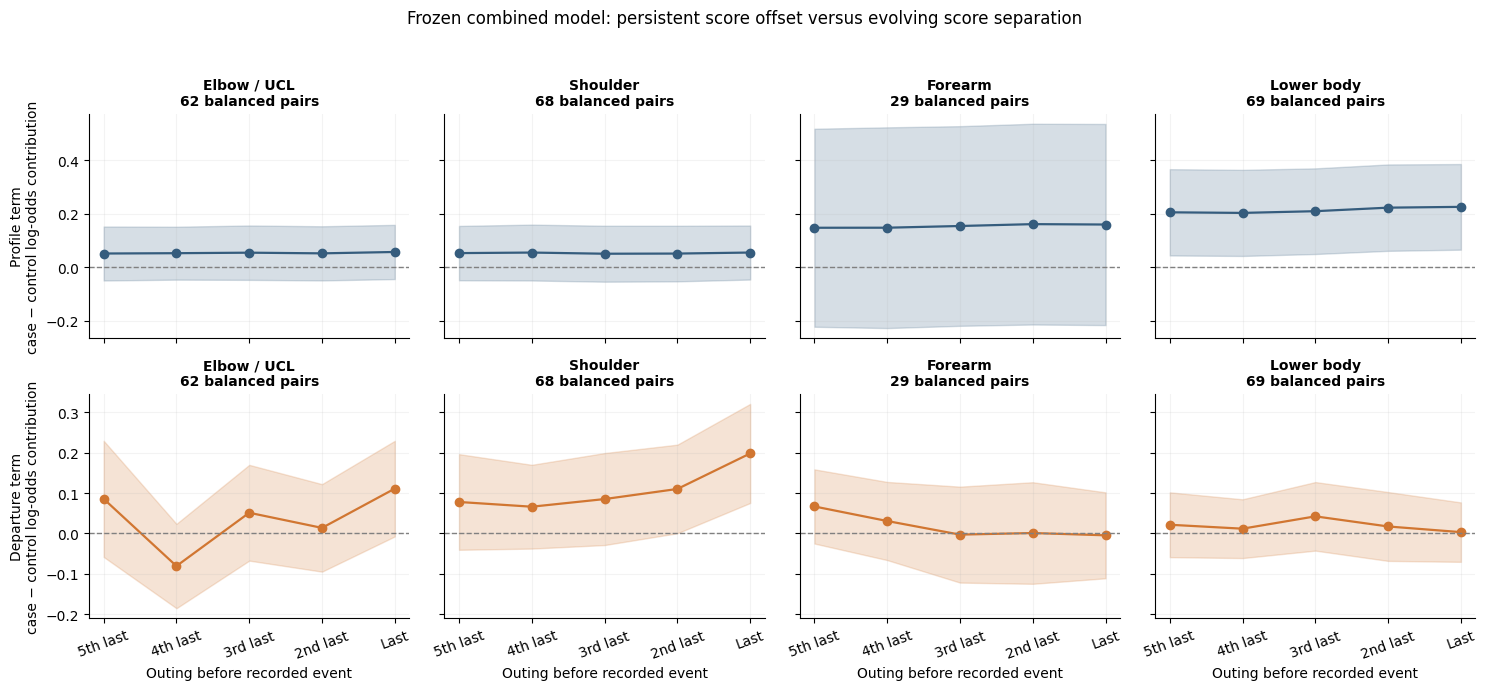

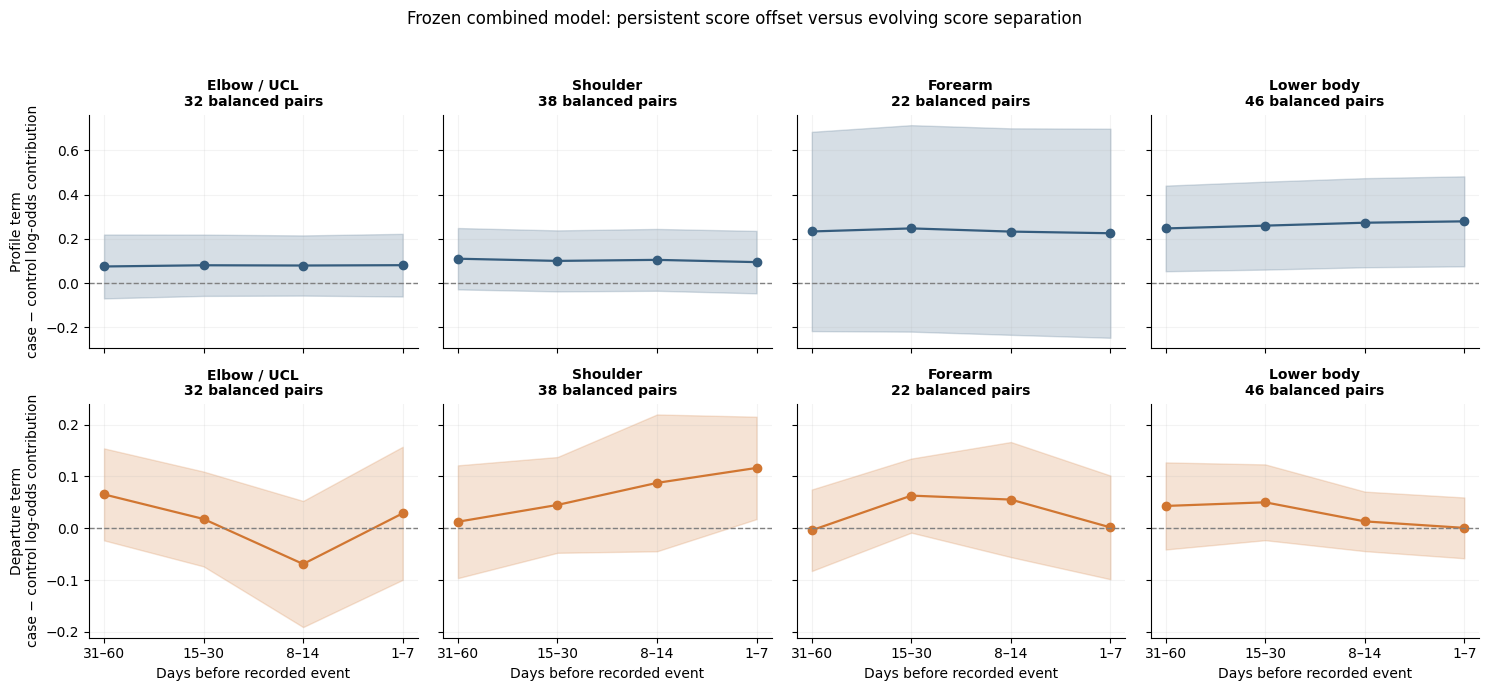

In [2]:
ensure_stage('models',a,events,spec,matches,force=False)
ensure_stage('scores',a,events,spec,matches,force=FORCE_RECOMPUTE)
display(read_table('score_alignment_coverage'))
display(read_table('contribution_identity'))
display(read_table('score_variation').query("partition=='test'"))
plots.score_trajectory_figure('appearance');plt.show()
plots.score_trajectory_figure('calendar');plt.show()

In [3]:
display(read_table('score_shape_contrasts').query("metric in ['average_separation','last_minus_first_separation']"))
display(read_table('score_appearance_lead_days'))
coeff=read_table('model_coefficients').query("variant=='Profile + Departure'")
display(coeff[~coeff.feature.str.startswith('missingindicator')].assign(
 absolute_coefficient=lambda f:f.standardized_log_odds.abs()).sort_values('absolute_coefficient',ascending=False).groupby('category').head(8))

,feature,mode,category,metric,mean,low,high,events,pitchers
0,profile_score,calendar,Elbow / UCL,average_separation,0.078791,-0.051640,0.214596,32,32
1,profile_score,calendar,Elbow / UCL,last_minus_first_separation,0.005842,-0.046451,0.057126,32,32
3,profile_score,calendar,Forearm,average_separation,0.234517,-0.224687,0.648840,22,22
4,profile_score,calendar,Forearm,last_minus_first_separation,-0.008068,-0.053863,0.035557,22,22
6,profile_score,calendar,Hand / wrist,average_separation,0.421486,0.103217,0.714516,13,12
7,profile_score,calendar,Hand / wrist,last_minus_first_separation,-0.067345,-0.197824,0.052028,13,12
9,profile_score,calendar,Lower body,average_separation,0.264548,0.071381,0.450023,46,43
10,profile_score,calendar,Lower body,last_minus_first_separation,0.032101,-0.016627,0.075265,46,43
12,profile_score,calendar,Other arm,average_separation,0.148176,-0.162551,0.391199,14,14
13,profile_score,calendar,Other arm,last_minus_first_separation,-0.010832,-0.041506,0.015080,14,14


,category,appearance_before,events,median_lead_days,q25,q75
0,Elbow / UCL,1,62,1.0,1.00,1.00
1,Elbow / UCL,2,62,5.5,4.00,7.00
2,Elbow / UCL,3,62,9.0,7.00,13.00
3,Elbow / UCL,4,62,12.5,10.00,19.00
4,Elbow / UCL,5,62,16.5,12.25,25.00
5,Forearm,1,29,1.0,1.00,3.00
6,Forearm,2,29,6.0,4.00,8.00
7,Forearm,3,29,10.0,6.00,13.00
8,Forearm,4,29,12.0,9.00,20.00
9,Forearm,5,29,23.0,13.00,27.00


,category,variant,feature,standardized_log_odds,absolute_coefficient
911,Forearm,Profile + Departure,throws_left,0.664149,0.664149
903,Forearm,Profile + Departure,release_x_avg_baseline_mean,-0.640889,0.640889
913,Forearm,Profile + Departure,days_since_mlb_debut,-0.550018,0.550018
39,Elbow / UCL,Profile + Departure,release_x_avg_baseline_mean,-0.423160,0.423160
908,Forearm,Profile + Departure,spin_avg_baseline_mean,0.409385,0.409385
2639,Hand / wrist,Profile + Departure,throws_left,-0.406380,0.406380
2631,Hand / wrist,Profile + Departure,release_x_avg_baseline_mean,0.392730,0.392730
47,Elbow / UCL,Profile + Departure,throws_left,0.367044,0.367044
910,Forearm,Profile + Departure,age_at_appearance,0.359431,0.359431
2640,Hand / wrist,Profile + Departure,observed_prior_mlb_starts,0.312512,0.312512


## Sensitivities motivated by the observed comparisons
Refit both representations on identical filtered rows for: complete P+D measurements; the same explicit P+D availability flags in both models; removal of final-six-day positive rows (never relabel them healthy); and measurement-only profiles without the five slow context fields. Repeat the missingness/timing checks with common workload/role/calendar adjustment for elbow/UCL and shoulder.

These checks address possible missingness artifacts, near-event diagnosis behavior and stable history effects. They are not new independent confirmatory studies. Shared-availability models disable duplicate automatic missingness flags. No learned transform sees validation/test outcomes.

Using verified sensitivity results (5 artifacts).


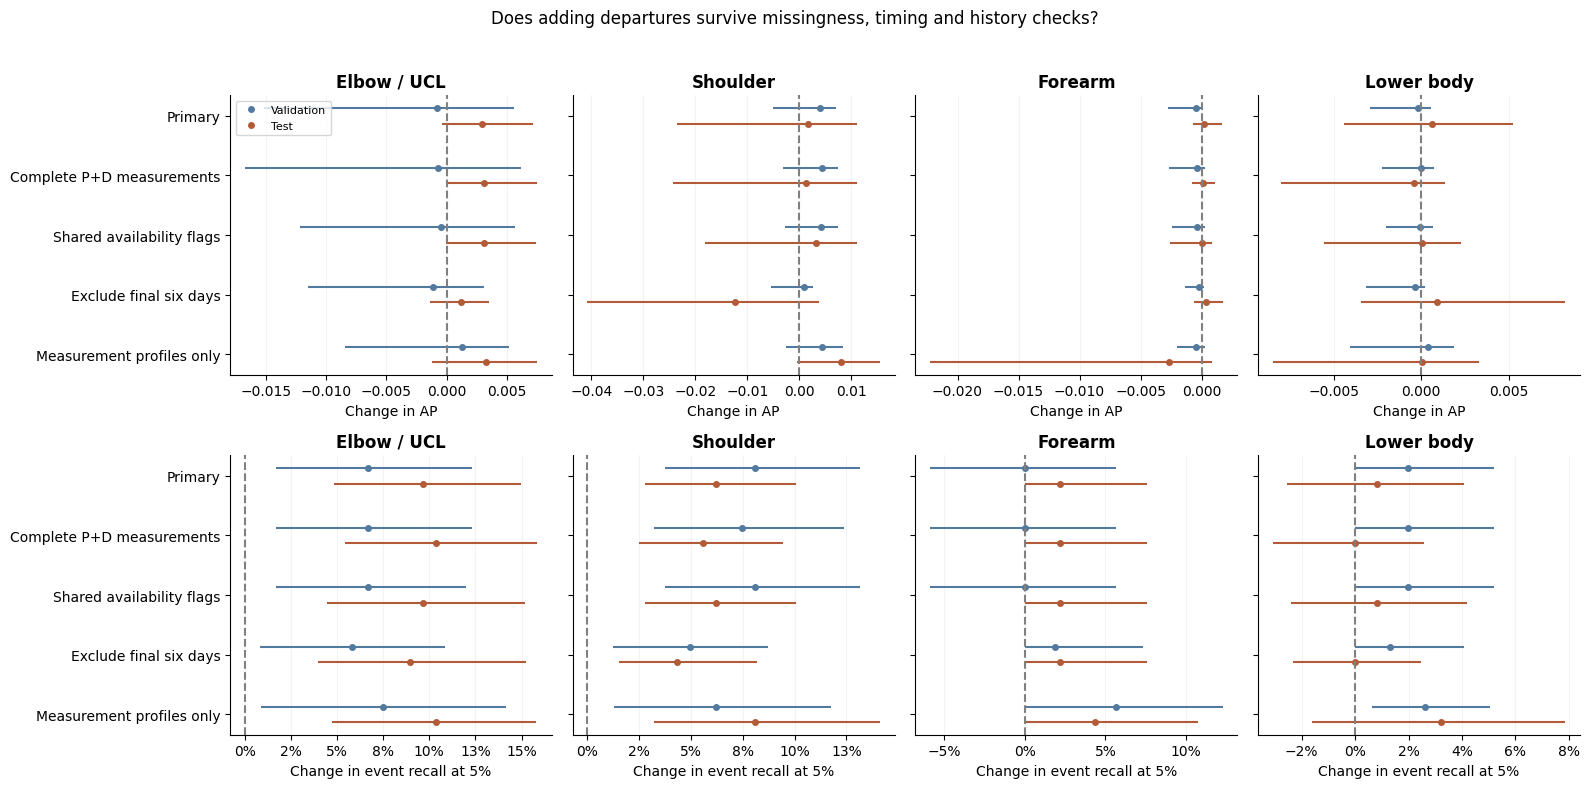

,category,condition,partition,rows,positive_rows,represented_events,original_rows
0,Elbow / UCL,Complete P+D measurements,train,80106,1424,223,81145
1,Elbow / UCL,Complete P+D measurements,validation,26531,594,89,26796
2,Elbow / UCL,Complete P+D measurements,test,27323,701,110,27665
3,Elbow / UCL,Shared availability flags,train,81145,1441,223,81145
4,Elbow / UCL,Shared availability flags,validation,26796,600,89,26796
5,Elbow / UCL,Shared availability flags,test,27665,708,110,27665
6,Elbow / UCL,Exclude final six days,train,80752,1048,201,81145
7,Elbow / UCL,Exclude final six days,validation,26625,429,80,26796
8,Elbow / UCL,Exclude final six days,test,27477,520,104,27665
9,Elbow / UCL,Measurement profiles only,train,81145,1441,223,81145


,category,partition,analysis,variant,reference,ap_difference,ap_low,ap_high,...,event_gained_events,event_lost_events,event_shared_detected_events,event_common_lead_mean,event_common_lead_low,event_common_lead_high,event_common_lead_events,event_common_lead_pitchers
0,Elbow / UCL,validation,Complete P+D measurements,Context + Profile + Departure,Context + Profile,0.001177,-0.001149,0.004662,...,3,3,13,1.384615,-0.307692,3.926923,13,13
1,Elbow / UCL,test,Complete P+D measurements,Context + Profile + Departure,Context + Profile,0.001293,-0.002064,0.005000,...,9,6,23,0.086957,-1.652174,1.544565,23,23
2,Elbow / UCL,validation,Shared availability flags,Context + Profile + Departure,Context + Profile,0.001888,-0.001973,0.008677,...,3,3,14,-0.142857,-0.428571,0.000000,14,14
3,Elbow / UCL,test,Shared availability flags,Context + Profile + Departure,Context + Profile,0.000988,-0.004266,0.005788,...,11,7,23,-1.478261,-3.804496,0.312154,23,22
4,Elbow / UCL,validation,Exclude final six days,Context + Profile + Departure,Context + Profile,0.000193,-0.002010,0.003827,...,7,0,14,-1.071429,-3.461538,0.000000,14,13
5,Elbow / UCL,test,Exclude final six days,Context + Profile + Departure,Context + Profile,-0.000331,-0.003064,0.001915,...,3,5,16,0.375000,0.000000,1.125000,16,16
6,Shoulder,validation,Complete P+D measurements,Context + Profile + Departure,Context + Profile,0.005482,0.000086,0.010773,...,9,1,16,0.062500,-1.200000,1.336581,16,15
7,Shoulder,test,Complete P+D measurements,Context + Profile + Departure,Context + Profile,0.006453,0.001315,0.012099,...,9,3,21,0.000000,-0.842105,1.233158,21,19
8,Shoulder,validation,Shared availability flags,Context + Profile + Departure,Context + Profile,0.006535,-0.000359,0.012250,...,7,1,19,1.947368,0.054020,4.379386,19,18
9,Shoulder,test,Shared availability flags,Context + Profile + Departure,Context + Profile,0.006305,0.001336,0.011723,...,7,4,22,-1.045455,-1.979348,-0.173913,22,19


In [4]:
ensure_stage('sensitivity',a,events,spec,matches,force=FORCE_RECOMPUTE)
plots.robustness_figure();plt.show()
display(read_table('sensitivity_coverage'))
display(read_table('adjusted_sensitivity_increment'))

## Training stability
Twelve paired whole-pitcher training bootstraps refit every preprocessing step and coefficient. The feature definitions and regularization remain frozen. Score-rank correlation and top-5% alert-set Jaccard compare each refit with that representation's unperturbed fit. Refit AP differences are descriptive perturbations, not 12 independent tests or an uncertainty interval for future generalization.

Using verified stability results (3 artifacts).


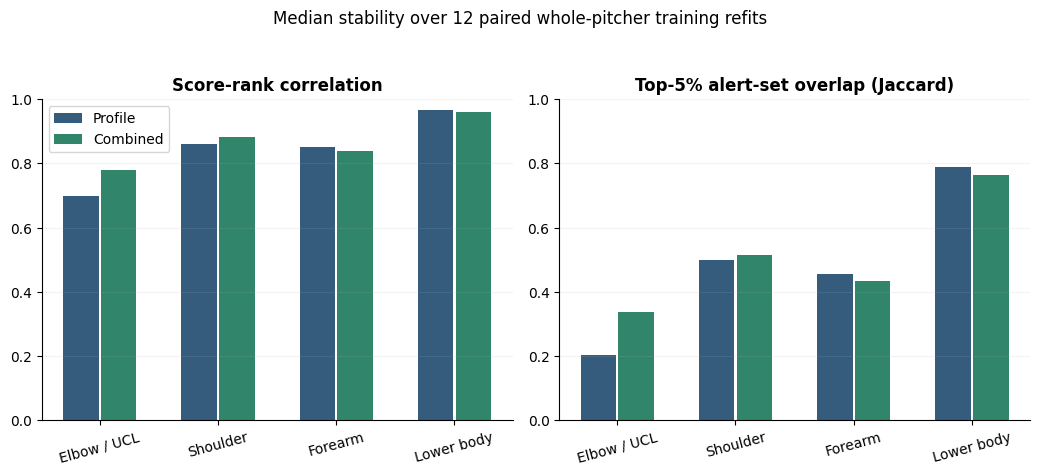

,category,partition,variant,refits,mean_ap,sd_ap,median_rank_correlation,median_alert_jaccard,mean_probability_shift
0,Elbow / UCL,test,Profile + Departure,12,0.030340,0.001791,0.778055,0.336180,0.005344
1,Elbow / UCL,test,Profile only,12,0.027709,0.001548,0.699283,0.203904,0.004969
2,Elbow / UCL,validation,Profile + Departure,12,0.026208,0.002256,0.784561,0.351843,0.005344
3,Elbow / UCL,validation,Profile only,12,0.025962,0.003198,0.718814,0.275860,0.004906
4,Forearm,test,Profile + Departure,12,0.019884,0.005707,0.838953,0.433780,0.005572
5,Forearm,test,Profile only,12,0.019575,0.004904,0.850174,0.454385,0.005369
6,Forearm,validation,Profile + Departure,12,0.012246,0.000932,0.822310,0.417245,0.004603
7,Forearm,validation,Profile only,12,0.012617,0.001030,0.832346,0.444502,0.004287
8,Lower body,test,Profile + Departure,12,0.046082,0.002180,0.961393,0.762894,0.008521
9,Lower body,test,Profile only,12,0.045741,0.001804,0.967673,0.788211,0.008090


mean       min       max
category    partition                               
Elbow / UCL test        0.002631  0.000857  0.004386
            validation  0.000246 -0.004061  0.001861
Forearm     test        0.000309 -0.001546  0.002174
            validation -0.000371 -0.000712 -0.000118
Lower body  test        0.000341 -0.000878  0.002898
            validation -0.000377 -0.000870  0.000260
Shoulder    test        0.003325 -0.004687  0.007618
            validation  0.002805 -0.001662  0.004493

In [5]:
ensure_stage('stability',a,events,spec,matches,force=FORCE_RECOMPUTE)
plots.stability_figure();plt.show()
display(read_table('stability_summary'))
display(read_table('training_refit_ap_differences').groupby(['category','partition']).ap_difference.agg(['mean','min','max']))

In [6]:
from src.injury_analysis.profile_report import write_synthesis
display(Markdown(write_synthesis()))

# Profile information versus short-term departure: findings

The fitted models use both types of information, but their incremental value differs by injury group and metric. Persistent profiles account for much of the Average Precision in several categories. Departures change which outings are alerted and offer the clearest additional evidence for shoulder injuries. This supports a mixture of profile association and short-term signal, not a demonstrated general injury-imminence detector.

## Direct comparison

All models use the original category-specific 30-day risk sets: train through 2021, validation 2022–2023, test 2024–2025, with the existing 60-day embargo. Both starters and relievers are included. The source cohort has 233,433 appearances; the supervised risk set is smaller and differs by injury category. No test outcomes choose feature blocks or model hyperparameters. These periods have already been examined in earlier analyses.

| Injury group | Profile AP | Departure AP | Combined AP | Original 62 AP | Profile → combined event recall |
|---|---:|---:|---:|---:|---:|
| Elbow / UCL | 0.0262 | 0.0306 | 0.0291 | 0.0426 | 2.8% → 12.4% |
| Shoulder | 0.0501 | 0.0431 | 0.0518 | 0.0559 | 9.3% → 15.5% |
| Forearm | 0.0174 | 0.0117 | 0.0175 | 0.0228 | 10.9% → 13.0% |
| Other arm | 0.0112 | 0.0099 | 0.0107 | 0.0101 | 8.9% → 11.1% |
| Trunk / neck | 0.0281 | 0.0182 | 0.0281 | 0.0273 | 15.3% → 17.6% |
| Lower body | 0.0461 | 0.0246 | 0.0467 | 0.0482 | 16.8% → 17.6% |
| Hand / wrist | 0.0083 | 0.0058 | 0.0078 | 0.0092 | 3.0% → 6.1% |

Event recall above requires an alert **7–30 days** before an event, at a budget of **5% of eligible outings**. Its denominator contains all qualifying events, including events with no usable warning opportunity.

Combined AP exceeds profile-only AP by point estimate for 5/7 test categories, but **0/7 paired 95% intervals exclude zero on the positive side**. Shoulder is the only category with a positive primary AP increment in both validation and test. Forearm and non-arm categories do not show a consistent, well-supported AP gain from departures.

## Event warnings and the workload adjustment

- **Elbow / UCL:** primary event-recall change is +6.7 percentage points in validation and +9.7 in test (test interval +4.8 to +15.0). With workload, role and calendar held common, it becomes +0.0 and +1.4 points; adjusted AP changes are +0.0011 and +0.0010.
- **Shoulder:** primary event-recall change is +8.1 percentage points in validation and +6.2 in test (test interval +2.8 to +10.1). With workload, role and calendar held common, it becomes +5.0 and +3.7 points; adjusted AP changes are +0.0045 and +0.0062.

The adjusted shoulder test AP difference is +0.0062 (95% interval +0.0010 to +0.0119); the validation interval includes zero. Elbow/UCL incremental gains are largely accounted for by shared workload/context. Adding eight strictly prior slopes to profile-plus-departure provides no clear additional AP benefit.

Profile scores repeatedly alert the same pitchers. For shoulder in test, the profile model alerts 67 distinct pitchers, versus 234 for combined, with the same 1,390 alerted outings. This helps explain why event recall can improve without a clear AP gain. It does not establish injury-specific timing: the unadjusted combined elbow/UCL and shoulder event-recall point estimates remain below the uniform-random alert expectation in both periods. The full budget curves retain that benchmark.

## Persistent scores versus approaching-event changes

An exact additive decomposition reconstructs the combined linear predictor as intercept + profile term + departure term, including source-specific missingness indicators. This is a decomposition of log-odds, not a fraction of causal risk or independent predictive importance. In test, 86–98% of profile-term variance lies between pitchers, compared with 4–9% for departure terms. Predictor blocks are correlated and are not biologically orthogonal.

Frozen combined-model scores are applied to the original **443 out-of-training matched pairs**, without rematching. Common complete measurement support leaves **68 shoulder pairs** with all five outings. The shoulder departure case-minus-control score increases 0.120 log-odds from the fifth-last to last outing (pitcher-bootstrap interval 0.007 to 0.260). Velocity departure has the strongest negative non-missingness standardized coefficient in the shoulder combined model: a lower-than-baseline velocity increases its score, conditional on the other predictors. Correlated coefficients are not causal effects.

The smaller balanced calendar cohort contains 38 shoulder pairs. Only the final **1–7-day** bin has a simultaneous difference band above zero; 8–14 days remains uncertain. The curves suggest late divergence, but do not establish a reliable earlier warning threshold. Appearance positions cannot be translated into fixed calendar lead time. Elbow/UCL, forearm and lower-body departure trajectories do not establish a comparable changing score pattern.

Lower-body profile scores show a persistent matched offset averaging 0.214 log-odds (0.061 to 0.371; 69 pairs). This is compatible with stable profile/history associations; it does not prove underlying susceptibility. The means used for “profile” are rolling summaries of at most 20 prior outings and can adapt to emerging injury.

## Robustness, probability quality and stability

- The primary arm event-recall improvements survive complete measurement rows, equal availability indicators, removal of final-six-day positive rows, and removal of the five history/context fields. However, **after workload adjustment and excluding final-six-day positives**, shoulder AP gains shrink to about +0.0006 in validation and +0.0005 in test, with intervals spanning zero. Its adjusted test event-recall increment is about +1.9 points, also uncertain. Thus the strongest adjusted discrimination result depends materially on the near-event window.
- Probability error changes are small. Shoulder test Brier loss improves by about 0.000091 in the primary comparison, but the corresponding validation interval includes zero. Reliability plots and mean bias do not support broad calibration improvement. For example, the combined lower-body test model predicts 4.32% mean risk against 2.30% observed. These are conditional risks in the selected analysis cohort, not population injury probabilities.
- Adding departures improves test rank/alert stability in elbow/UCL and modestly in shoulder, but slightly reduces it in forearm and lower body across 12 paired training-pitcher bootstrap refits. All transforms are refitted on each training resample. Twelve perturbations are diagnostics, not 12 independent generalization tests.
- There is no consistent evidence of **earlier** warnings for the same events. Jointly detected test shoulder events have a mean lead change of −1.8 days, with an interval spanning zero. Comparing conditional median lead across different detected events can be misleading; the paired common-event comparison is saved separately.
- Validation-derived thresholds produce different test alert rates; retrospective top-5% performance is not a deployable fixed-threshold promise.

## Interpretation and next experiment

The answer is **some combination of both**, with strong dependence on injury category. Profile/history information explains most of the observed AP for lower-body and several other categories. Shoulder provides the best evidence that departures add information beyond profile and workload, although much of its discrimination gain is very close to the recorded event. Elbow/UCL benefits in event coverage relative to a static-profile warning policy, but has weak evidence of additional information once workload/context is included. These results do not establish that the model detects biological onset or causal susceptibility.

A defensible next step is to freeze a shoulder-focused, explicitly ≥7-day-warning comparison before evaluating a new chronological period. Retain profile/workload and uniform-random alert benchmarks, inspect near-event reporting dates, and calibrate only within training/validation data if calibration is added. The 2024–2025 period here is exploratory, not a fresh confirmatory holdout.

## Scope and limitations

P is 8 prior measurement means + age, handedness, observed starts, days since debut and prior reported IL count. D is the corresponding 8 current pitcher z-scores. C is 15 workload fields + current role + month, held common rather than forced into either conceptual block. Missing flags are extra learned design columns; all raw NULLs remain untouched. Arm angle is omitted because long-history coverage is unavailable. Current-outing departures are available only after the outing. Pitcher z-scores include the pitcher-specific denominator and do not mathematically remove every stable characteristic.

All models retain the existing median/scaling/L2-logistic C=1 framework, with train-only preprocessing and tight numerical convergence. This tests these representations in the existing linear model; it is not a universal test that nonlinear or interaction-based departure signals cannot help. AP/Brier intervals condition on frozen fitted models; event intervals also condition on fixed budget allocations. Matched time bands adjust within each trajectory, not across every injury and outcome. Small groups, repeated use of controls, multiple comparisons and retrospectively refined injury records limit inference. IL/event dates are observable proxies, not verified biological onset.

Brier loss measures both discrimination and probability reliability; it is not a calibration-only score. See the [scikit-learn calibration guide](https://scikit-learn.org/1.8/modules/calibration.html).

## Figures and reproducibility

Figures are exported as PNG and PDF in [figures](figures/). Recommended for presentation: [incremental AP/event recall](figures/02_incremental_ap_and_event_recall.pdf), [alert-budget curves](figures/03_event_recall_alert_budgets.pdf), and [calendar score trajectories](figures/05_score_trajectories_calendar.pdf). The tables retain every model, category, partition, event denominator and uncertainty interval.

Run the two notebooks with `.venv/bin/python scripts/run_injury_analysis_notebooks.py --suite injury-profiles`. Cached stages verify source/config/code/output fingerprints before reuse; set FORCE_RECOMPUTE=True in the notebooks to reproduce fitting. The DuckDB database, canonical injuries, original cohorts, matching and preceding results remain unchanged.
